# DTW-RL Complete Experiment Analysis

Analisis PDR, delay, handover, energi CPU/LPM/TX/RX, adaptive τ, routing evaluation, controller/MMDEW timing, dan diagnostik resource overhead.

In [9]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Mesin analisis revisi

PDR utama = **PDR yang dilaporkan server**, bukan PDR end-to-end tervalidasi. Pilih FINAL_STATS terakhir, fallback SUMMARY lalu paket. PDR reconstructed tetap diagnostik. CF3/CF4 pada log mengungguli konstanta fallback. Stack errors tetap wajib diperiksa.


In [10]:
#!/usr/bin/env python3
"""Analyze complete DTW-RL Contiki-NG CSV logs.

The input must contain ``time``, ``node``, and ``message`` columns.  The
parser supports the complete instrumentation used by DTWRL3021:

* UDP client/server packet delivery, delay, and RSSI
* custom handover (HO) and convergence events
* TE cumulative Energest counters (CPU/LPM/TX/RX)
* CT controller timing, RC routing evaluations, and MT MMDEW timing
* TB/TS/TQ behavior and CF1-CF5 configuration records
* stack, CSMA, restart, and other diagnostic records

Primary PDR is the server-reported FINAL_STATS (last SUMMARY/packet fallback).
It is not a validated end-to-end delivery ratio. Unique (node,seq) matching
is retained separately as a diagnostic, never substituted for server PDR.

Energy conversion uses configurable Zolertia Z1 constants.  With current in
mA, voltage in V, and time in seconds, the result is directly in mJ.
"""

from __future__ import annotations

import argparse
import re
from pathlib import Path
from typing import Iterable

import numpy as np
import pandas as pd


INT = r"([0-9]+)"
FLOAT = r"(-?[0-9]+(?:\.[0-9]+)?)"

# Common Z1/MSP430 + CC2420 values. Override from the command line when the
# experiment uses calibrated/device-specific values.
DEFAULT_TICKS_PER_SECOND = 32768.0
DEFAULT_VOLTAGE_V = 3.0
DEFAULT_CPU_MA = 1.8
DEFAULT_LPM_MA = 0.0545
DEFAULT_TX_MA = 17.4
DEFAULT_RX_MA = 18.8


def safe_float(value) -> float:
    try:
        return np.nan if pd.isna(value) else float(value)
    except (TypeError, ValueError):
        return np.nan


def stats(values: Iterable[float], prefix: str) -> dict[str, float]:
    s = pd.to_numeric(pd.Series(list(values), dtype="object"), errors="coerce").dropna()
    if s.empty:
        return {
            f"{prefix}_n": 0,
            f"{prefix}_mean": np.nan,
            f"{prefix}_sd": np.nan,
            f"{prefix}_median": np.nan,
            f"{prefix}_min": np.nan,
            f"{prefix}_max": np.nan,
            f"{prefix}_p95": np.nan,
        }
    return {
        f"{prefix}_n": int(len(s)),
        f"{prefix}_mean": float(s.mean()),
        f"{prefix}_sd": float(s.std(ddof=1)) if len(s) > 1 else np.nan,
        f"{prefix}_median": float(s.median()),
        f"{prefix}_min": float(s.min()),
        f"{prefix}_max": float(s.max()),
        f"{prefix}_p95": float(s.quantile(0.95)),
    }


def extract_number(messages: pd.Series, pattern: str) -> pd.Series:
    return pd.to_numeric(messages.str.extract(pattern, expand=False), errors="coerce")


def last_hex_group(ip: str) -> float:
    match = re.search(r":([0-9a-fA-F]+)$", str(ip).strip())
    return float(int(match.group(1), 16)) if match else np.nan


def parse_clock(value: str) -> tuple[float, bool]:
    parts = str(value).strip().split(":")
    try:
        if len(parts) == 2:
            return int(parts[0]) * 60.0 + float(parts[1]), True
        if len(parts) == 3:
            return int(parts[0]) * 3600.0 + int(parts[1]) * 60.0 + float(parts[2]), False
    except (TypeError, ValueError):
        pass
    return np.nan, False


def unwrap_timestamps(series: pd.Series) -> tuple[pd.Series, int]:
    values: list[float] = []
    offset = 0.0
    previous: float | None = None
    rollovers = 0
    for text in series:
        raw, minute_format = parse_clock(text)
        if np.isnan(raw):
            values.append(np.nan)
            continue
        if minute_format and previous is not None and raw < previous - 300.0:
            offset += 3600.0
            rollovers += 1
        values.append(raw + offset)
        previous = raw
    return pd.Series(values, index=series.index, dtype="float64"), rollovers


def read_log(path: Path) -> tuple[pd.DataFrame, int]:
    df = pd.read_csv(
        path,
        dtype={"time": "string", "node": "Int64", "message": "string"},
        engine="python",
        on_bad_lines="error",
    )
    required = {"time", "node", "message"}
    if not required.issubset(df.columns):
        raise ValueError(f"{path}: required columns are time,node,message")
    df = df[["time", "node", "message"]].copy()
    df["message"] = df["message"].fillna("")
    df["row_order"] = np.arange(len(df), dtype=np.int64)
    df["time_s"], rollovers = unwrap_timestamps(df["time"])
    return df, rollovers


def parse_tag(df: pd.DataFrame, tag: str) -> pd.DataFrame:
    mask = df["message"].str.contains(rf"\b{re.escape(tag)},", regex=True, na=False)
    return df.loc[mask, ["row_order", "time_s", "node", "message"]].copy()


def ticks_to_mj(ticks: pd.Series, current_ma: float, voltage_v: float, ticks_per_second: float) -> pd.Series:
    return pd.to_numeric(ticks, errors="coerce") / ticks_per_second * current_ma * voltage_v


def analyze_run(
    path: Path,
    run: str,
    sink_node: int,
    ticks_per_second: float,
    voltage_v: float,
    cpu_ma: float,
    lpm_ma: float,
    tx_ma: float,
    rx_ma: float,
) -> dict[str, pd.DataFrame | dict]:
    df, rollovers = read_log(path)
    msg = df["message"]

    # Preserve every configuration field, including C numeric suffixes.
    config_rows = []
    for _, row in df.iterrows():
        match = re.search(r"\b(CF[1-5]),(.*)", row["message"])
        if match:
            for key, raw in re.findall(r"(\w+)=([^,\"\s]+)", match[2]):
                clean = re.sub(r"(?<=\d)(?:[fF]|[uU][lL]*|[lL]+)$", "", raw)
                config_rows.append(dict(run=run, tag=match[1], node=row["node"], key=key, value=clean, raw_value=raw))
    config = pd.DataFrame(config_rows, columns=["run", "tag", "node", "key", "value", "raw_value"])
    def configured(key, fallback):
        values = pd.to_numeric(config.loc[config["key"] == key, "value"], errors="coerce").dropna().unique()
        if len(values) > 1:
            raise ValueError(f"Conflicting configuration values: {key}: {values}")
        return float(values[0]) if len(values) else fallback
    ticks_per_second = configured("rtimer_hz", ticks_per_second)
    clock_hz = configured("clock_hz", np.nan)
    voltage_v = configured("voltage", voltage_v)
    cpu_ma, lpm_ma = configured("cpu_mA", cpu_ma), configured("lpm_mA", lpm_ma)
    tx_ma, rx_ma = configured("tx_mA", tx_ma), configured("rx_mA", rx_ma)
    if min(ticks_per_second, voltage_v, cpu_ma, lpm_ma, tx_ma, rx_ma) <= 0:
        raise ValueError("Energy/timing conversion constants must be positive")

    server = df.loc[(df["node"] == sink_node) & msg.str.contains(r"UDP-Server.*PDR=", regex=True)].copy()
    server["server_pdr_pct"] = extract_number(server["message"], rf"PDR={FLOAT}%")
    server["record_type"] = np.select(
        [server["message"].str.contains("FINAL_STATS"), server["message"].str.contains("UDP_SUMMARY")],
        ["FINAL_STATS", "UDP_SUMMARY"], default="packet")
    for col, pattern in {"received": rf"(?:Received|Recv)={INT}", "lost": rf"Lost={INT}",
                         "total": rf"Total={INT}", "delay_avg_ms": rf"DelayAvg={FLOAT}ms"}.items():
        server[col] = extract_number(server["message"], pattern)
    selected = None
    for kind in ("FINAL_STATS", "UDP_SUMMARY", "packet"):
        candidates = server.loc[(server["record_type"] == kind) & server["server_pdr_pct"].notna()]
        if not candidates.empty:
            selected = candidates.iloc[-1]
            break
    server.insert(0, "run", run)

    # UDP packet events and defensible multi-sender PDR.
    sent = df.loc[
        msg.str.contains(r"\[INFO:\s*UDP-Client\].*Sent Seq=", regex=True, na=False),
        ["row_order", "time_s", "node", "message"],
    ].copy()
    sent["seq"] = extract_number(sent["message"], rf"Sent Seq={INT}").astype("Int64")
    sent = sent.dropna(subset=["node", "seq"])
    sent_duplicates = int(sent.duplicated(["node", "seq"]).sum())
    sent = sent.drop_duplicates(["node", "seq"], keep="first")

    recv = df.loc[
        (df["node"] == sink_node) & msg.str.contains(r"\[INFO:\s*UDP-Server\].*From .*Seq=", regex=True, na=False),
        ["row_order", "time_s", "node", "message"],
    ].copy()
    recv["source_ip"] = recv["message"].str.extract(r"From\s+([^,]+),\s*Seq=", expand=False)
    recv["source_node"] = recv["source_ip"].apply(last_hex_group).astype("Int64")
    recv["seq"] = extract_number(recv["message"], rf"Seq={INT}").astype("Int64")
    recv["delay_ms"] = extract_number(recv["message"], rf"Delay={FLOAT}ms")
    recv["rssi_dbm"] = extract_number(recv["message"], rf"RSSI={FLOAT}dBm")
    recv["server_pdr_pct_diagnostic"] = extract_number(recv["message"], rf"PDR={FLOAT}%")
    recv = recv.dropna(subset=["source_node", "seq"])
    recv_duplicates = int(recv.duplicated(["source_node", "seq"]).sum())
    recv = recv.drop_duplicates(["source_node", "seq"], keep="first")

    sent_keys = pd.MultiIndex.from_frame(sent[["node", "seq"]])
    recv_keys = pd.MultiIndex.from_frame(
        recv[["source_node", "seq"]].rename(columns={"source_node": "node"})
    )
    recv["matches_sent"] = recv_keys.isin(sent_keys)
    matched_received = int(recv["matches_sent"].sum())
    unmatched_received = int((~recv["matches_sent"]).sum())

    packet_events = recv.rename(columns={"node": "sink_node"}).copy()
    packet_events.insert(0, "run", run)
    packet_events = packet_events[
        ["run", "row_order", "time_s", "sink_node", "source_node", "seq",
         "delay_ms", "rssi_dbm", "matches_sent", "server_pdr_pct_diagnostic"]
    ]

    # Handover: custom HO event only. ConvStart/ConvDone are kept separately.
    handover = df.loc[
        msg.str.contains(r"\bHO,\d+,delay_ms=\d+", regex=True, na=False),
        ["row_order", "time_s", "node", "message"],
    ].copy()
    handover["handover_counter"] = extract_number(handover["message"], rf"\bHO,{INT},delay_ms=").astype("Int64")
    handover["inter_handover_interval_ms"] = extract_number(handover["message"], rf"delay_ms={INT}")
    handover["handover_delay_ms"] = handover["inter_handover_interval_ms"]
    handover.insert(0, "run", run)

    conv = df.loc[
        msg.str.contains(r"\bHO,Conv(?:Start|Done)\b", regex=True, na=False),
        ["row_order", "time_s", "node", "message"],
    ].copy()
    conv["event"] = np.where(conv["message"].str.contains("ConvStart", na=False), "start", "done")
    conv["reported_value_raw"] = extract_number(conv["message"], rf"(?:t|d)={INT}")
    conv.insert(0, "run", run)

    # Complete telemetry tables.
    te = parse_tag(df, "TE")
    te_patterns = {
        "window": rf"\bTE,W={INT}", "reported_node": rf"\bN={INT}",
        "tau_centisec": rf"\btau_c={INT}", "action": r"\ba=(-?\d+)",
        "hold": rf"\bH={INT}", "evidence": rf"\bE={INT}",
        "cpu_ticks": rf"\bC={INT}", "lpm_ticks": rf"\bL={INT}",
        "tx_ticks": rf"\bT={INT}", "rx_ticks": rf"\bR={INT}",
    }
    for column, pattern in te_patterns.items():
        te[column] = extract_number(te["message"], pattern)
    te["reported_node"] = te["reported_node"].fillna(te["node"])
    te["tau_next_s"] = te["tau_centisec"] / 100.0
    behavior = parse_tag(df, "TB")
    behavior["window"] = extract_number(behavior["message"], rf"\bTB,W={INT}")
    behavior["reported_node"] = extract_number(behavior["message"], rf"\bN={INT}").fillna(behavior["node"])
    behavior["tau_used_s"] = extract_number(behavior["message"], rf"\bused_c={INT}") / 100.0
    behavior["tau_next_s"] = extract_number(behavior["message"], rf"\bnext_c={INT}") / 100.0
    behavior["action"] = extract_number(behavior["message"], r"\ba=(-?\d+)")
    behavior["hold"] = extract_number(behavior["message"], rf"\bH={INT}")
    behavior["evidence"] = extract_number(behavior["message"], rf"\bE={INT}")
    behavior.insert(0, "run", run)
    for tag, fields in (("TS", {"inv_m": "inverse_trust", "de_m": "energy_feature", "I_m": "instability"}),
                        ("TQ", {"reward_m": "reward", "eps_m": "epsilon", "target_c": "tau_target_s"})):
        extra = parse_tag(df, tag)
        extra["window"] = extract_number(extra["message"], rf"\bW={INT}")
        extra["reported_node"] = extract_number(extra["message"], rf"\bN={INT}").fillna(extra["node"])
        for key, column in fields.items():
            extra[column] = extract_number(extra["message"], rf"\b{key}=(-?\d+)") / (100 if key.endswith("_c") else 1000)
        behavior = behavior.merge(extra[["reported_node", "window", *fields.values()]],
                                  on=["reported_node", "window"], how="outer", validate="one_to_one")
    behavior["run"] = run
    behavior["decision"] = np.select([behavior["hold"] == 1, behavior["action"] == -1,
                                      behavior["action"] == 0, behavior["action"] == 1],
                                     ["HOLD", "FIXED", "DECREASE", "INCREASE"], default="UNKNOWN")
    difference = behavior["tau_next_s"] - behavior["tau_used_s"]
    behavior["actual_tau_change"] = np.select([difference > 0, difference < 0, difference == 0],
                                             ["INCREASE", "DECREASE", "UNCHANGED"], default="UNKNOWN")
    if not behavior.empty:
        te = te.merge(behavior[["reported_node", "window", "tau_used_s"]],
                      on=["reported_node", "window"], how="left")
    else:
        te["tau_used_s"] = np.nan
    # No substitution of next tau for the interval that just elapsed.
    te["tau_s"] = te["tau_used_s"]
    for state, current in (("cpu", cpu_ma), ("lpm", lpm_ma), ("tx", tx_ma), ("rx", rx_ma)):
        te[f"{state}_cumulative_mj"] = ticks_to_mj(te[f"{state}_ticks"], current, voltage_v, ticks_per_second)
    te["total_cumulative_mj"] = te[
        ["cpu_cumulative_mj", "lpm_cumulative_mj", "tx_cumulative_mj", "rx_cumulative_mj"]
    ].sum(axis=1, min_count=4)
    te = te.sort_values(["reported_node", "row_order"])
    te["window_gap"] = te.groupby("reported_node")["window"].diff().ne(1)
    te["observed_interval_s"] = te.groupby("reported_node")["time_s"].diff()
    for state in ("cpu", "lpm", "tx", "rx", "total"):
        col = f"{state}_cumulative_mj"
        delta = te.groupby("reported_node", observed=True)[col].diff()
        te[f"{state}_window_mj"] = delta.mask((delta < 0) | te["window_gap"])
    te["energy_counter_reset"] = te.groupby("reported_node")[[f"{s}_ticks" for s in ("cpu", "lpm", "tx", "rx")]].diff().lt(0).any(axis=1)
    te.loc[te["energy_counter_reset"], [f"{s}_window_mj" for s in ("cpu", "lpm", "tx", "rx", "total")]] = np.nan
    te["mean_power_mw"] = te["total_window_mj"] / te["observed_interval_s"].where(te["observed_interval_s"] > 0)
    active_radio = pd.to_numeric(
        te["tx_window_mj"] / (tx_ma * voltage_v)
        + te["rx_window_mj"] / (rx_ma * voltage_v),
        errors="coerce",
    ).astype("float64")
    elapsed_system = pd.to_numeric(
        te["cpu_window_mj"] / (cpu_ma * voltage_v)
        + te["lpm_window_mj"] / (lpm_ma * voltage_v),
        errors="coerce",
    ).astype("float64")
    te["radio_duty_cycle_pct"] = np.where(
        elapsed_system > 0, 100.0 * active_radio / elapsed_system, np.nan
    )
    te.insert(0, "run", run)

    ct = parse_tag(df, "CT")
    ct["window"] = extract_number(ct["message"], rf"\bCT,W={INT}")
    ct["reported_node"] = extract_number(ct["message"], rf"\bN={INT}").fillna(ct["node"])
    ct["controller_ticks"] = extract_number(ct["message"], rf"\bT={INT}")
    ct["controller_time_us"] = ct["controller_ticks"] / ticks_per_second * 1e6
    ct.insert(0, "run", run)

    rc = parse_tag(df, "RC")
    rc["window"] = extract_number(rc["message"], rf"\bRC,W={INT}")
    rc["reported_node"] = extract_number(rc["message"], rf"\bN={INT}").fillna(rc["node"])
    rc["routing_evaluations"] = extract_number(rc["message"], rf"\bC={INT}")
    rc.insert(0, "run", run)

    mt = parse_tag(df, "MT")
    mt["window"] = extract_number(mt["message"], rf"\bMT,W={INT}")
    mt["reported_node"] = extract_number(mt["message"], rf"\bN={INT}").fillna(mt["node"])
    mt["mmdew_samples"] = extract_number(mt["message"], rf"\bS={INT}")
    mt["mmdew_total_ticks"] = extract_number(mt["message"], rf"\bT={INT}")
    mt["mmdew_total_us"] = mt["mmdew_total_ticks"] / ticks_per_second * 1e6
    mt["mmdew_mean_us_per_sample"] = np.where(
        mt["mmdew_samples"] > 0, mt["mmdew_total_us"] / mt["mmdew_samples"], np.nan
    )
    mt.insert(0, "run", run)

    # Merge telemetry by node/window. MT is sampled, so missing MT is expected.
    te_out = te.rename(columns={"reported_node": "metric_node"}).drop(columns=["node", "message"], errors="ignore")
    window = te_out.copy()
    for table, columns in (
        (ct, ["reported_node", "window", "controller_ticks", "controller_time_us"]),
        (rc, ["reported_node", "window", "routing_evaluations"]),
        (mt, ["reported_node", "window", "mmdew_samples", "mmdew_total_ticks", "mmdew_total_us", "mmdew_mean_us_per_sample"]),
    ):
        if not table.empty:
            add = table[columns].rename(columns={"reported_node": "metric_node"})
            window = window.merge(add, on=["metric_node", "window"], how="outer", validate="one_to_one")
    window = window.merge(behavior[["reported_node", "window", "decision", "actual_tau_change", "inverse_trust", "energy_feature", "instability", "reward", "epsilon", "tau_target_s"]].rename(columns={"reported_node": "metric_node"}), on=["metric_node", "window"], how="outer", validate="one_to_one")
    window["run"] = run
    window["mt_aggregation_windows"] = configured("mt_windows", np.nan)

    # CF configuration: preserve raw values and strip C float suffixes.

    # Per-node table. Nodes with zero handovers must remain in the denominator.
    client_nodes = sorted((set(df["node"].dropna().astype(int))) - {sink_node})
    nodes = pd.DataFrame({"node": client_nodes})
    sent_n = sent.groupby("node").size().rename("sent_unique")
    # Count only receive keys that can be matched to a submitted client packet.
    recv_n = recv.loc[recv["matches_sent"]].groupby("source_node").size().rename("received_unique")
    ho_n = handover.groupby("node").size().rename("handover_events")
    nodes = nodes.merge(sent_n, on="node", how="left").merge(recv_n, left_on="node", right_on="source_node", how="left")
    nodes = nodes.drop(columns=["source_node"], errors="ignore").merge(ho_n, on="node", how="left")
    for column in ("sent_unique", "received_unique", "handover_events"):
        nodes[column] = nodes[column].fillna(0).astype(int)
    nodes["lost"] = nodes["sent_unique"] - nodes["received_unique"]
    nodes["pdr_pct"] = np.where(nodes["sent_unique"] > 0, 100.0 * nodes["received_unique"] / nodes["sent_unique"], np.nan)
    nodes = nodes.rename(columns={"pdr_pct": "pdr_pct_reconstructed"})

    delay_n = recv.groupby("source_node")["delay_ms"].agg(["mean", "median", "std", "min", "max"]).add_prefix("delay_ms_")
    nodes = nodes.merge(delay_n, left_on="node", right_index=True, how="left")

    energy_node_rows = []
    for node, sub in te.groupby("reported_node", observed=True):
        if int(node) == sink_node:
            continue
        sub = sub.sort_values("row_order")
        first, last = sub.iloc[0], sub.iloc[-1]
        item = {"node": int(node), "energy_records": int(len(sub))}
        for state in ("cpu", "lpm", "tx", "rx", "total"):
            item[f"{state}_since_boot_mj"] = safe_float(last[f"{state}_cumulative_mj"])
            item[f"{state}_observed_interval_mj"] = safe_float(last[f"{state}_cumulative_mj"] - first[f"{state}_cumulative_mj"])
            if sub["energy_counter_reset"].any():
                item[f"{state}_since_boot_mj"] = np.nan
                item[f"{state}_observed_interval_mj"] = np.nan
        item["radio_duty_cycle_mean_pct"] = safe_float(sub["radio_duty_cycle_pct"].mean())
        item["tau_mean_s"] = safe_float(sub["tau_s"].mean())
        item["tau_min_s"] = safe_float(sub["tau_s"].min())
        item["tau_max_s"] = safe_float(sub["tau_s"].max())
        valid = sub[["tau_s", "total_window_mj"]].dropna()
        item["tau_energy_pearson_r"] = safe_float(valid["tau_s"].corr(valid["total_window_mj"], method="pearson")) if len(valid) > 1 else np.nan
        item["tau_energy_spearman_rho"] = safe_float(valid["tau_s"].corr(valid["total_window_mj"], method="spearman")) if len(valid) > 1 else np.nan
        energy_node_rows.append(item)
    energy_nodes = pd.DataFrame(energy_node_rows)
    if not energy_nodes.empty:
        nodes = nodes.merge(energy_nodes, on="node", how="left")

    if not ct.empty:
        ct_n = ct.groupby("reported_node")["controller_time_us"].agg(["count", "mean", "std", "min", "max"])
        ct_n.columns = [f"controller_time_us_{c}" for c in ct_n.columns]
        nodes = nodes.merge(ct_n, left_on="node", right_index=True, how="left")
    if not rc.empty:
        rc_n = rc.groupby("reported_node")["routing_evaluations"].agg(["sum", "mean", "max"])
        rc_n.columns = [f"routing_evaluations_{c}" for c in rc_n.columns]
        nodes = nodes.merge(rc_n, left_on="node", right_index=True, how="left")
    if not mt.empty:
        mt_n = mt.groupby("reported_node").agg(
            mmdew_samples_sum=("mmdew_samples", "sum"),
            mmdew_total_us_sum=("mmdew_total_us", "sum"),
            mmdew_mean_us_per_sample=("mmdew_mean_us_per_sample", "mean"),
        )
        mt_n["mmdew_mean_us_per_sample"] = mt_n["mmdew_total_us_sum"] / mt_n["mmdew_samples_sum"].where(mt_n["mmdew_samples_sum"] > 0)
        nodes = nodes.merge(mt_n, left_on="node", right_index=True, how="left")
    if not behavior.empty:
        counts = pd.crosstab(behavior["reported_node"], behavior["decision"]).add_prefix("decision_")
        nodes = nodes.merge(counts, left_on="node", right_index=True, how="left")
    nodes.insert(0, "run", run)

    # Diagnostic error/restart records.
    diagnostic_patterns = {
        "stack_error": r"\[ERR\s*:\s*Stack",
        "csma_error": r"\[(?:ERR|WARN)\s*:\s*CSMA",
        "node_start": r"Starting Contiki-NG",
        "neighbor_allocation_drop": r"could not allocate neighbor",
        "local_repair": r"Starting a local instance repair",
        "udp_no_connection": r"udp: no matching connection found",
    }
    error_parts = []
    diagnostic_counts = {}
    for kind, pattern in diagnostic_patterns.items():
        part = df.loc[msg.str.contains(pattern, regex=True, case=False, na=False), ["row_order", "time_s", "node", "message"]].copy()
        part.insert(0, "run", run)
        part.insert(1, "event_type", kind)
        diagnostic_counts[kind] = int(len(part))
        error_parts.append(part)
    errors = pd.concat(error_parts, ignore_index=True) if error_parts else pd.DataFrame()

    valid_time = df["time_s"].dropna()
    duration_s = float(valid_time.max() - valid_time.min()) if len(valid_time) else np.nan
    duration_min = duration_s / 60.0 if duration_s > 0 else np.nan
    sent_count = int(len(sent))
    pdr = 100.0 * matched_received / sent_count if sent_count else np.nan

    energy_total_since_boot = safe_float(nodes["total_since_boot_mj"].sum(min_count=1)) if "total_since_boot_mj" in nodes else np.nan
    energy_mean_node = safe_float(nodes["total_since_boot_mj"].mean()) if "total_since_boot_mj" in nodes else np.nan
    energy_total_observed = safe_float(nodes["total_observed_interval_mj"].sum(min_count=1)) if "total_observed_interval_mj" in nodes else np.nan

    valid_corr = window[["tau_s", "total_window_mj"]].dropna() if {"tau_s", "total_window_mj"}.issubset(window) else pd.DataFrame()
    mt_samples_total = float(mt["mmdew_samples"].sum()) if not mt.empty else np.nan
    mt_ticks_total = float(mt["mmdew_total_ticks"].sum()) if not mt.empty else np.nan
    mt_weighted_us = (mt_ticks_total / ticks_per_second * 1e6 / mt_samples_total
                      if mt_samples_total and mt_samples_total > 0 else np.nan)
    summary = {
        "run": run,
        "source_file": str(path),
        "simulation_duration_s": duration_s,
        "timestamp_rollovers_corrected": rollovers,
        "sink_node": sink_node,
        "client_nodes": len(client_nodes),
        "sent_unique": sent_count,
        "received_unique_matched": matched_received,
        "lost_reconstructed": max(sent_count - matched_received, 0),
        "pdr_pct_reconstructed": pdr,
        "pdr_pct": safe_float(selected["server_pdr_pct"]) if selected is not None else np.nan,
        "server_pdr_pct": safe_float(selected["server_pdr_pct"]) if selected is not None else np.nan,
        "pdr_definition": "server_reported_not_validated_end_to_end",
        "server_pdr_record_type": selected["record_type"] if selected is not None else "missing",
        "server_pdr_time_s": selected["time_s"] if selected is not None else np.nan,
        "server_received_at_snapshot": selected["received"] if selected is not None else np.nan,
        "server_lost_estimated_at_snapshot": selected["lost"] if selected is not None else np.nan,
        "server_delay_avg_ms": selected["delay_avg_ms"] if selected is not None else np.nan,
        "udp_no_connection_lines": diagnostic_counts["udp_no_connection"],
        "energy_timing_ticks_per_second": ticks_per_second,
        "sent_duplicate_lines": sent_duplicates,
        "received_duplicate_lines": recv_duplicates,
        "received_without_matching_sent": unmatched_received,
        "handover_events": int(len(handover)),
        "handover_mean_per_node_including_zero": safe_float(nodes["handover_events"].mean()),
        "handover_nodes_with_event": int((nodes["handover_events"] > 0).sum()),
        "te_records": int(len(te)), "ct_records": int(len(ct)),
        "rc_records": int(len(rc)), "mt_records": int(len(mt)),
        "energy_nodes": int(len(energy_nodes)),
        "energy_total_since_boot_logged_nodes_mj": energy_total_since_boot,
        "energy_mean_per_node_since_boot_mj": energy_mean_node,
        "energy_total_observed_interval_logged_nodes_mj": energy_total_observed,
        "tau_energy_pearson_r_all_windows": safe_float(valid_corr["tau_s"].corr(valid_corr["total_window_mj"], method="pearson")) if len(valid_corr) > 1 else np.nan,
        "tau_energy_spearman_rho_all_windows": safe_float(valid_corr["tau_s"].corr(valid_corr["total_window_mj"], method="spearman")) if len(valid_corr) > 1 else np.nan,
        "energy_counter_resets": int(te["energy_counter_reset"].sum()) if not te.empty else 0,
        "stack_error_lines": diagnostic_counts["stack_error"],
        "csma_error_lines": diagnostic_counts["csma_error"],
        "node_start_lines": diagnostic_counts["node_start"],
        "nodes_started_more_than_once": int((df.loc[msg.str.contains("Starting Contiki-NG", na=False)].groupby("node").size() > 1).sum()),
        "neighbor_allocation_drops": diagnostic_counts["neighbor_allocation_drop"],
        "local_repairs": diagnostic_counts["local_repair"],
        "stack_errors_per_min": diagnostic_counts["stack_error"] / duration_min if duration_min else np.nan,
    }
    summary.update(stats(recv.loc[recv["matches_sent"], "delay_ms"], "packet_delay_ms"))
    summary.update(stats(recv.loc[recv["matches_sent"], "rssi_dbm"], "packet_rssi_dbm"))
    summary.update(stats(handover["handover_delay_ms"], "handover_delay_ms"))
    summary.update(stats(handover["inter_handover_interval_ms"], "inter_handover_interval_ms"))
    summary.update(stats(te["tau_s"], "tau_s"))
    summary.update(stats(te["total_window_mj"], "energy_window_mj"))
    summary.update(stats(ct["controller_time_us"], "controller_time_us"))
    summary.update(stats(rc["routing_evaluations"], "routing_evaluations_per_window"))
    summary.update(stats(mt["mmdew_mean_us_per_sample"], "mmdew_time_us_per_sample"))
    summary["mmdew_weighted_us_per_sample"] = mt_weighted_us
    for label in ("HOLD", "FIXED", "INCREASE", "DECREASE", "UNKNOWN"):
        summary[f"decision_{label.lower()}_count"] = int((behavior["decision"] == label).sum())
    for label in ("INCREASE", "DECREASE", "UNCHANGED", "UNKNOWN"):
        summary[f"actual_tau_{label.lower()}_count"] = int((behavior["actual_tau_change"] == label).sum())
    for column in ("evidence", "instability", "reward", "epsilon"):
        summary.update(stats(behavior[column], column))

    issues: list[dict] = []
    def add_issue(code: str, severity: str, detail: str) -> None:
        issues.append({"run": run, "severity": severity, "issue_code": code, "detail": detail})
    add_issue("SERVER_PDR_LIMITATION", "warning", "Primary PDR is server-reported; global last_seq mixes senders. Not validated end-to-end.")
    if selected is None:
        add_issue("SERVER_PDR_MISSING", "error", "No server PDR found; primary remains NaN, never replaced by reconstructed PDR")
    if diagnostic_counts["udp_no_connection"]:
        add_issue("UDP_NO_CONNECTION", "warning", f"{diagnostic_counts['udp_no_connection']} UDP no matching connection errors")
    if not {"rtimer_hz", "cpu_mA", "lpm_mA", "tx_mA", "rx_mA", "voltage"}.issubset(set(config["key"])):
        add_issue("CONVERSION_FALLBACKS", "warning", "Missing CF conversion fields use CLI/default values; confirm firmware constants")
    if not conv.empty:
        add_issue("CONVERGENCE_UNVALIDATED", "warning", "Raw start/done events only; no validated convergence duration")
    if te["window_gap"].sum() > te["reported_node"].nunique():
        add_issue("ENERGY_WINDOW_GAPS", "warning", "Nonconsecutive TE windows excluded from per-window energy")
    if diagnostic_counts["stack_error"]:
        add_issue("STACK_ERRORS_PRESENT", "warning", f"{diagnostic_counts['stack_error']} stack-check error lines")
    if diagnostic_counts["node_start"] > len(set(df.loc[msg.str.contains("Starting Contiki-NG", na=False), "node"].dropna())):
        add_issue("NODE_RESTART_SUSPECTED", "error", "At least one node printed the startup banner more than once")
    if unmatched_received:
        add_issue("RECEIVE_WITHOUT_SENT_KEY", "warning", f"{unmatched_received} receive keys have no matching client sent key")
    if te.empty:
        add_issue("TE_MISSING", "warning", "No energy telemetry found")
    if int(te["energy_counter_reset"].sum()) if not te.empty else 0:
        add_issue("ENERGY_COUNTER_RESET", "error", "At least one cumulative energy counter decreased")
    if sink_node not in set(te["reported_node"].dropna()):
        add_issue("SINK_ENERGY_NOT_INCLUDED", "info", "Energy totals cover logged client nodes, not the sink")

    return {
        "summary": summary,
        "node_metrics": nodes,
        "packet_events": packet_events,
        "server_metrics": server,
        "controller_events": ct,
        "routing_events": rc,
        "mmdew_events": mt,
        "handover_events": handover[["run", "row_order", "time_s", "node", "handover_counter", "inter_handover_interval_ms"]],
        "behavior_events": behavior,
        "convergence_events": conv,
        "window_metrics": window,
        "config": config,
        "diagnostics": pd.DataFrame(issues, columns=["run", "severity", "issue_code", "detail"]),
        "error_events": errors,
    }


def metric_definitions() -> pd.DataFrame:
    return pd.DataFrame(
        [
            ("pdr_pct / server_pdr_pct (run summary)", "Server-reported PDR: last FINAL_STATS, else last UDP_SUMMARY, else last packet; not validated end-to-end. Never averaged across cumulative snapshots."),
            ("node pdr_pct_reconstructed", "Per-source matched delivery diagnostic; global server PDR is never assigned to individual nodes."),
            ("decision", "TB: H=1 HOLD; otherwise a=-1 FIXED, a=0 DECREASE, a=1 INCREASE; distinct from actual tau change."),
            ("instability / reward / epsilon", "TS/TQ fixed-point fields divided by 1000; target_c divided by 100."),
            ("mean_power_mw", "Window energy divided by observed interval seconds; not controller-only power."),
            ("configuration", "CF1-CF5 preserved; logged conversion constants take precedence over CLI fallbacks."),
            ("pdr_pct_reconstructed", "unique received matching (node,seq) / unique sent (node,seq)"),
            ("packet_delay_ms", "Delay printed by UDP server for unique matched packets"),
            ("inter_handover_interval_ms", "Elapsed time since the previous HO event; not switching latency"),
            ("handover_mean_per_node_including_zero", "custom HO events / all eligible client nodes, including zero-HO nodes"),
            ("total_since_boot_mj", "last cumulative TE counter converted to mJ"),
            ("total_observed_interval_mj", "last minus first recorded cumulative energy for each node"),
            ("total_window_mj", "difference between consecutive cumulative TE records; first record is NaN"),
            ("radio_duty_cycle_pct", "estimated radio active time divided by CPU+LPM elapsed time"),
            ("controller_time_us", "CT ticks converted using ticks_per_second"),
            ("mmdew_mean_us_per_sample", "MT total ticks / MT sample count"),
            ("routing_evaluations", "RC counter reported for a controller window"),
        ],
        columns=["metric", "definition"],
    )


def run_analysis(files: list[Path], output_dir: Path, args: argparse.Namespace) -> None:
    output_dir.mkdir(parents=True, exist_ok=True)
    results = []
    for index, path in enumerate(files, start=1):
        print(f"[{index}/{len(files)}] Reading {path}")
        results.append(analyze_run(
            path=path, run=path.stem, sink_node=args.sink_node,
            ticks_per_second=args.ticks_per_second, voltage_v=args.voltage,
            cpu_ma=args.cpu_ma, lpm_ma=args.lpm_ma, tx_ma=args.tx_ma, rx_ma=args.rx_ma,
        ))

    summary = pd.DataFrame([result["summary"] for result in results])
    summary.to_csv(output_dir / "run_summary.csv", index=False)
    for key, filename in (
        ("node_metrics", "node_metrics.csv"),
        ("packet_events", "packet_events.csv"),
        ("server_metrics", "server_metrics.csv"),
        ("controller_events", "controller_events.csv"),
        ("routing_events", "routing_events.csv"),
        ("mmdew_events", "mmdew_events.csv"),
        ("handover_events", "handover_events.csv"),
        ("behavior_events", "behavior_events.csv"),
        ("convergence_events", "convergence_events.csv"),
        ("window_metrics", "window_metrics.csv"),
        ("config", "configuration.csv"),
        ("diagnostics", "diagnostics.csv"),
        ("error_events", "error_events.csv"),
    ):
        tables = [result[key] for result in results if not result[key].empty]
        (pd.concat(tables, ignore_index=True) if tables else pd.DataFrame()).to_csv(output_dir / filename, index=False)
    metric_definitions().to_csv(output_dir / "metric_definitions.csv", index=False)
    print(f"Done. Results written to: {output_dir}")


def build_parser() -> argparse.ArgumentParser:
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("csv_files", nargs="+", type=Path, help="One or more Contiki CSV logs")
    parser.add_argument("-o", "--output-dir", type=Path, default=Path("dtwrl_analysis"))
    parser.add_argument("--sink-node", type=int, default=30)
    parser.add_argument("--ticks-per-second", type=float, default=DEFAULT_TICKS_PER_SECOND)
    parser.add_argument("--voltage", type=float, default=DEFAULT_VOLTAGE_V)
    parser.add_argument("--cpu-ma", type=float, default=DEFAULT_CPU_MA)
    parser.add_argument("--lpm-ma", type=float, default=DEFAULT_LPM_MA)
    parser.add_argument("--tx-ma", type=float, default=DEFAULT_TX_MA)
    parser.add_argument("--rx-ma", type=float, default=DEFAULT_RX_MA)
    return parser


def main() -> None:
    parser = build_parser()
    args = parser.parse_args()
    missing = [str(path) for path in args.csv_files if not path.exists()]
    if missing:
        parser.error("Missing input file(s): " + ", ".join(missing))
    if args.ticks_per_second <= 0:
        parser.error("--ticks-per-second must be positive")
    run_analysis(args.csv_files, args.output_dir, args)



## 2. Konfigurasi lokasi data dan konstanta Z1
Ubah `INPUT_DIR` sesuai folder CSV di Google Drive. Semua file yang cocok dengan `FILE_PATTERN` akan dianalisis.

In [11]:
from types import SimpleNamespace

INPUT_DIR = Path('/content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/Ablasi/tau/CSV/tau3/mob5')  # UBAH SESUAI FOLDER
FILE_PATTERN = 'DTWRL*.csv'
OUTPUT_DIR = INPUT_DIR / 'hasil_analisis_lengkap1'

CSV_FILES = sorted(INPUT_DIR.glob(FILE_PATTERN))
assert CSV_FILES, f'Tidak ada file {FILE_PATTERN} di {INPUT_DIR}'
print(f'Ditemukan {len(CSV_FILES)} file:')
for f in CSV_FILES:
    print(' -', f.name)

SETTINGS = SimpleNamespace(
    sink_node=30, ticks_per_second=32768.0, voltage=3.0,
    cpu_ma=1.8, lpm_ma=0.0545, tx_ma=17.4, rx_ma=18.8,
)

Ditemukan 3 file:
 - DTWRL101.csv
 - DTWRL201.csv
 - DTWRL301.csv


## 3. Jalankan ekstraksi seluruh CSV

In [12]:
run_analysis(CSV_FILES, OUTPUT_DIR, SETTINGS)

[1/3] Reading /content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/Ablasi/tau/CSV/tau3/mob5/DTWRL101.csv
[2/3] Reading /content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/Ablasi/tau/CSV/tau3/mob5/DTWRL201.csv
[3/3] Reading /content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/Ablasi/tau/CSV/tau3/mob5/DTWRL301.csv
Done. Results written to: /content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/Ablasi/tau/CSV/tau3/mob5/hasil_analisis_lengkap1


## 4. Periksa hasil utama

In [13]:
summary = pd.read_csv(OUTPUT_DIR / 'run_summary.csv')
nodes = pd.read_csv(OUTPUT_DIR / 'node_metrics.csv')
diagnostics = pd.read_csv(OUTPUT_DIR / 'diagnostics.csv')

display(summary)
print('\nDiagnostik:')
display(diagnostics)

,run,source_file,simulation_duration_s,timestamp_rollovers_corrected,sink_node,client_nodes,sent_unique,received_unique_matched,lost_reconstructed,pdr_pct_reconstructed,...,reward_min,reward_max,reward_p95,epsilon_n,epsilon_mean,epsilon_sd,epsilon_median,epsilon_min,epsilon_max,epsilon_p95
0,DTWRL101,/content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/A...,3598.658,1,30,29,9875,405,9470,4.101266,...,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN
1,DTWRL201,/content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/A...,3598.775,1,30,29,5061,39,5022,0.770599,...,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN
2,DTWRL301,/content/drive/MyDrive/LOG CONTIKI-NG/DTW-RL/A...,3598.676,1,30,29,3384,582,2802,17.198582,...,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN



Diagnostik:


,run,severity,issue_code,detail
0,DTWRL101,warning,SERVER_PDR_LIMITATION,Primary PDR is server-reported; global last_se...
1,DTWRL101,warning,UDP_NO_CONNECTION,4285 UDP no matching connection errors
2,DTWRL101,warning,CONVERSION_FALLBACKS,Missing CF conversion fields use CLI/default v...
3,DTWRL101,warning,CONVERGENCE_UNVALIDATED,Raw start/done events only; no validated conve...
4,DTWRL101,warning,STACK_ERRORS_PRESENT,5977 stack-check error lines
5,DTWRL101,info,SINK_ENERGY_NOT_INCLUDED,"Energy totals cover logged client nodes, not t..."
6,DTWRL201,warning,SERVER_PDR_LIMITATION,Primary PDR is server-reported; global last_se...
7,DTWRL201,warning,UDP_NO_CONNECTION,2403 UDP no matching connection errors
8,DTWRL201,warning,CONVERSION_FALLBACKS,Missing CF conversion fields use CLI/default v...
9,DTWRL201,warning,CONVERGENCE_UNVALIDATED,Raw start/done events only; no validated conve...


## 5. Ringkasan metrik utama untuk perbandingan run

In [14]:
KEY_METRICS = [
    'run', 'simulation_duration_s', 'server_pdr_pct',
    'packet_delay_ms_mean', 'packet_delay_ms_p95',
    'handover_events', 'handover_mean_per_node_including_zero',
    'energy_mean_per_node_since_boot_mj', 'energy_total_since_boot_logged_nodes_mj',
    'tau_s_mean', 'routing_evaluations_per_window_mean',
    'controller_time_us_mean', 'mmdew_weighted_us_per_sample',
    'stack_error_lines', 'nodes_started_more_than_once',
]
display(summary[[c for c in KEY_METRICS if c in summary.columns]])

,run,simulation_duration_s,server_pdr_pct,packet_delay_ms_mean,packet_delay_ms_p95,handover_events,handover_mean_per_node_including_zero,energy_mean_per_node_since_boot_mj,energy_total_since_boot_logged_nodes_mj,tau_s_mean,routing_evaluations_per_window_mean,controller_time_us_mean,mmdew_weighted_us_per_sample,stack_error_lines,nodes_started_more_than_once
0,DTWRL101,3598.658,73.0,326.465672,636.8,2105,72.586207,204273.087402,5.923920e+06,NaN,3.242844,2276.498652,22050.056799,5977,0
1,DTWRL201,3598.775,100.0,475.567568,773.0,1125,38.793103,204155.418801,5.920507e+06,NaN,2.754360,2252.093666,22323.956015,4474,0
2,DTWRL301,3598.676,100.0,294.295547,617.0,1543,53.206897,204042.755209,5.917240e+06,NaN,2.134067,2243.455040,22320.030337,4534,0


## 6. Grafik pemeriksaan cepat

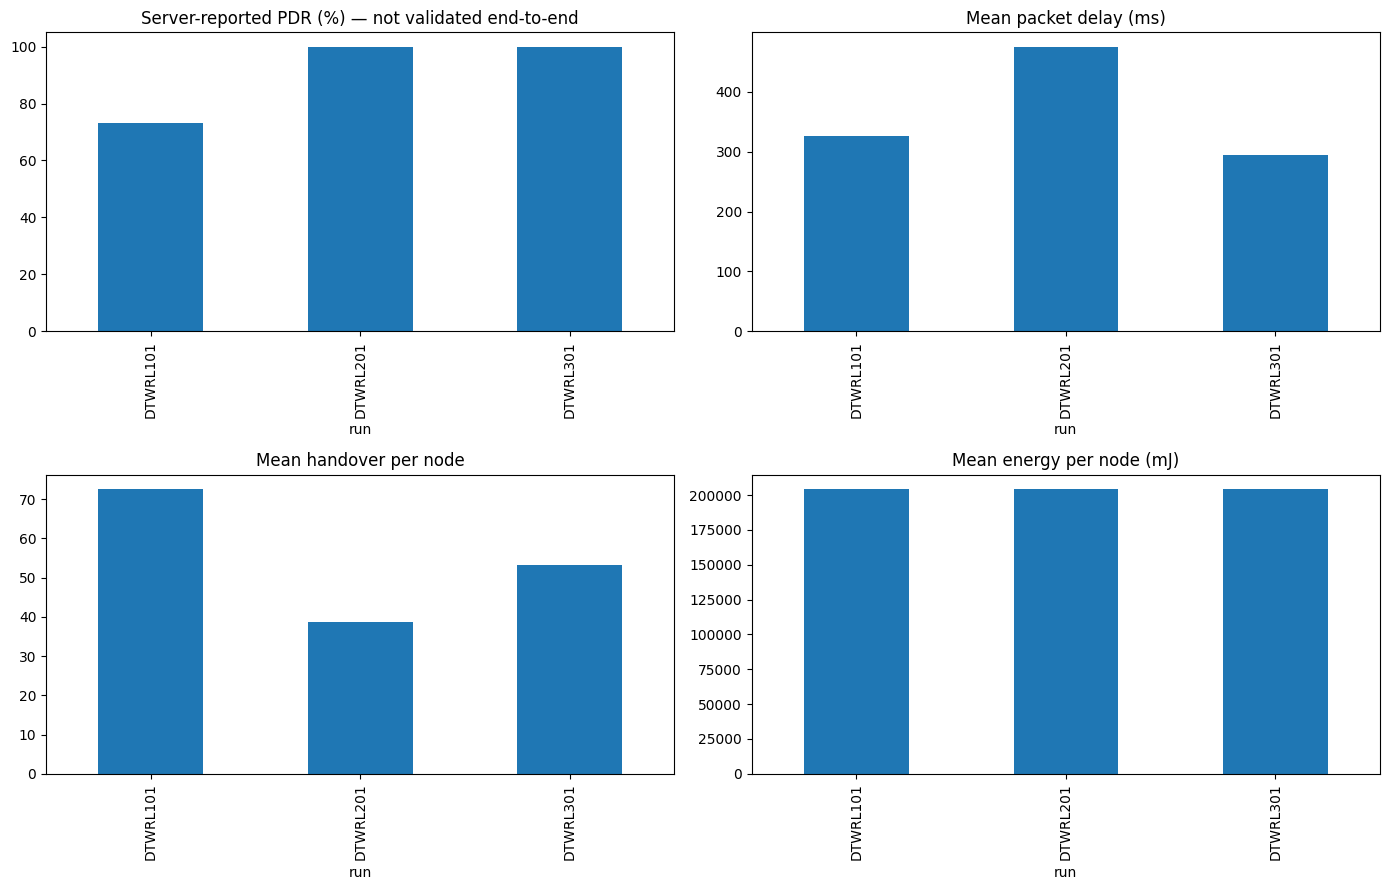

In [15]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
summary.plot.bar(x='run', y='server_pdr_pct', ax=axes[0,0], legend=False, title='Server-reported PDR (%) — not validated end-to-end')
summary.plot.bar(x='run', y='packet_delay_ms_mean', ax=axes[0,1], legend=False, title='Mean packet delay (ms)')
summary.plot.bar(x='run', y='handover_mean_per_node_including_zero', ax=axes[1,0], legend=False, title='Mean handover per node')
summary.plot.bar(x='run', y='energy_mean_per_node_since_boot_mj', ax=axes[1,1], legend=False, title='Mean energy per node (mJ)')
plt.tight_layout()
plt.show()

## Catatan hasil

`server_metrics.csv` menyimpan semua snapshot server; `run_summary.csv` memakai satu snapshot dengan sumber/waktu eksplisit. PDR per-node tetap bernama `pdr_pct_reconstructed` (diagnostik). `behavior_events.csv` memuat TB/TS/TQ. CT, RC, MT juga diekspor terpisah. MT adalah sampel agregat, bukan satu window. Convergence tetap event mentah, belum durasi tervalidasi. Data code size/static RAM tidak berasal dari log ini.
